In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.integrate import trapezoid
from scipy.signal import butter, sosfiltfilt, welch
from IPython.display import display

# Support the project, workspace, or notebook working directory.
roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'project']
PROJECT_DIR = next(p for p in roots if (p / '02_raw_data' / 'Set 11').is_dir())
ANALYSIS_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / '02_raw_data' / 'Set 11'
SPIKE_DIR = DATA_DIR / 'Spike Data'
RESULTS_DIR = ANALYSIS_DIR / 'results'
INPUT_RESULTS = RESULTS_DIR / '01_input_check'
FILTER_RESULTS = RESULTS_DIR / '02_preprocessing'
for folder in [INPUT_RESULTS, FILTER_RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

tools_dir = PROJECT_DIR / '01_original_submissions' / 'analysis-tools' / 'NeuroData' / 'Python3'
sys.path.insert(0, str(tools_dir))
import OpenEphys

print('Data:', DATA_DIR)
print('Results:', RESULTS_DIR)

In [ ]:
mapping = loadmat(DATA_DIR / 'chanMap.mat')
channel_map = pd.DataFrame({
    'channel': mapping['chanMap'].ravel().astype(int),
    'connected': mapping['connected'].ravel().astype(bool),
    'map_x': mapping['xcoords'].ravel().astype(float),
    'map_y': mapping['ycoords'].ravel().astype(float),
}).sort_values('channel').reset_index(drop=True)

record_dtype = np.dtype([
    ('timestamp', '<i8'), ('sample_count', '<u2'), ('recording_number', '>u2'),
    ('samples', '>i2', (1024,)), ('marker', 'u1', (10,)),
])
record_marker = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 255], dtype='u1')
records_by_channel = {}
file_rows = []

for channel in channel_map['channel']:
    path = SPIKE_DIR / f'100_CH{channel}.continuous'
    file_size = path.stat().st_size
    if (file_size - 1024) % record_dtype.itemsize:
        raise ValueError(f'CH{channel} contains an incomplete record.')
    with path.open('rb') as stream:
        header = OpenEphys.readHeader(stream)
    records = np.memmap(path, dtype=record_dtype, mode='r', offset=1024)
    if np.any(records['sample_count'] != 1024):
        raise ValueError(f'CH{channel} contains an unexpected record sample count.')
    if np.any(records['marker'] != record_marker):
        raise ValueError(f'CH{channel} contains an invalid record marker.')
    records_by_channel[int(channel)] = records
    file_rows.append({
        'channel': int(channel), 'file': path.name, 'bytes': file_size,
        'sample_rate_hz': float(header['sampleRate']),
        'gain_uv_per_adc': float(header['bitVolts']), 'records_in_file': len(records),
        'last_block_all_zero': bool(np.all(records['samples'][-1] == 0)),
    })

inventory = pd.DataFrame(file_rows)
first_records = records_by_channel[int(channel_map['channel'].iloc[0])]
timestamps = np.asarray(first_records['timestamp'])
for channel, records in records_by_channel.items():
    if not np.array_equal(records['timestamp'], timestamps):
        raise ValueError(f'CH{channel} has timestamps that differ from other channels.')
if inventory['sample_rate_hz'].nunique() != 1:
    raise ValueError('Sampling rates differ between channels.')
sample_rate = float(inventory['sample_rate_hz'].iloc[0])
if float(mapping['fs'].ravel()[0]) != sample_rate:
    raise ValueError('Sampling rates differ between the channel map and recording.')

trailing_blank = bool(inventory['last_block_all_zero'].all() and np.diff(timestamps)[-1] > 1024)
valid_records = len(first_records) - int(trailing_blank)
valid_samples = valid_records * 1024
valid_timestamps = timestamps[:valid_records]
timestamp_steps = np.diff(valid_timestamps)
gaps = np.flatnonzero(timestamp_steps > 1024)
overlaps = np.flatnonzero(timestamp_steps < 1024)
recording_summary = pd.DataFrame([{
    'connected_channels': int(channel_map['connected'].sum()),
    'sample_rate_hz': sample_rate,
    'duration_seconds': valid_samples / sample_rate,
    'tail_reason': 'all channels zero after timestamp gap' if trailing_blank else 'none',
    'gaps_in_valid_recording': len(gaps), 'overlaps_in_valid_recording': len(overlaps),
}])
recording_summary.to_csv(INPUT_RESULTS / 'recording_summary.csv', index=False)
display(recording_summary[['connected_channels', 'sample_rate_hz', 'duration_seconds']].T.rename(columns={0: 'value'}))
if len(gaps) or len(overlaps):
    raise ValueError('Resolve timestamp gaps or overlaps before continuing.')

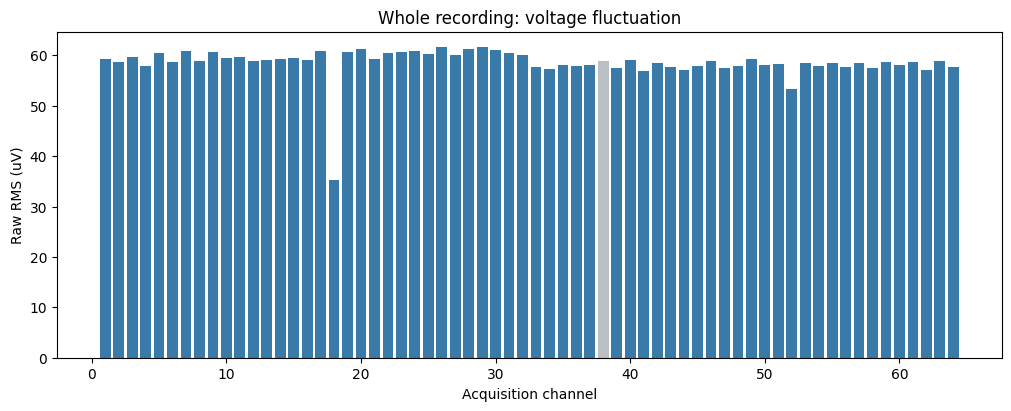

Channels used: 63; excluded: [38]
Connected channels with ADC saturation: []


In [3]:
quality_rows = []
gains = inventory.set_index('channel')['gain_uv_per_adc'].to_dict()
for channel, records in records_by_channel.items():
    adc = records['samples'][:valid_records].reshape(-1)
    voltage = adc.astype(np.float32) * gains[channel]
    median_uv = float(np.median(voltage))
    centered = voltage - median_uv
    quality_rows.append({
        'channel': channel, 'median_uv': median_uv,
        'raw_mad_scale_uv': float(np.median(np.abs(centered)) / 0.67448975),
        'raw_rms_uv': float(np.sqrt(np.mean(centered.astype(np.float64) ** 2))),
        'min_uv': float(voltage.min()), 'max_uv': float(voltage.max()),
        'saturated_samples': int(np.count_nonzero((adc == -32768) | (adc == 32767))),
        'unchanged_adjacent_fraction': float(np.mean(adc[1:] == adc[:-1])),
        'constant_whole_recording': bool(adc.min() == adc.max()),
    })

channels = channel_map.merge(inventory, on='channel').merge(pd.DataFrame(quality_rows), on='channel')
channels['include'] = channels['connected'] & ~channels['constant_whole_recording']
channels['decision'] = np.select(
    [~channels['connected'], channels['constant_whole_recording'], channels['saturated_samples'] > 0],
    ['exclude: disconnected in channel map', 'exclude: entire signal constant', 'retain; inspect saturation'],
    default='retain; no amplitude-based exclusion',
)
channels.to_csv(INPUT_RESULTS / 'channels.csv', index=False)
active_channels = channels.loc[channels['include'], 'channel'].to_numpy(dtype=int)

def read_voltage(start, stop, channel_ids=active_channels):
    # Read a slice using zero-based sample indices in the valid recording.
    first_block = start // 1024
    last_block = (stop + 1023) // 1024
    offset = start - first_block * 1024
    return np.stack([
        records_by_channel[int(ch)]['samples'][first_block:last_block].reshape(-1)[offset:offset + stop - start]
        for ch in channel_ids
    ]).astype(np.float32) * np.array([gains[int(ch)] for ch in channel_ids], dtype=np.float32)[:, None]

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.bar(channels['channel'], channels['raw_rms_uv'], color=np.where(channels['include'], '#397AA8', '#B9BFC5'))
ax.set(xlabel='Acquisition channel', ylabel='Raw RMS (uV)', title='Whole recording: voltage fluctuation')
fig.savefig(INPUT_RESULTS / 'channel_overview.png', dpi=170)
plt.show()

print(f'Channels used: {len(active_channels)}; excluded:', channels.loc[~channels['include'], 'channel'].tolist())
print('Connected channels with ADC saturation:', channels.loc[channels['include'] & (channels['saturated_samples'] > 0), 'channel'].tolist())


In [4]:
LOW_HZ, HIGH_HZ = 300, 6000
FILTER_ORDER = 3
WINDOW_SECONDS, N_WINDOWS, RANDOM_SEED = 5, 6, 11
PADDING_SECONDS = 0.1
WELCH_SECONDS = 1

sos = butter(FILTER_ORDER, [LOW_HZ, HIGH_HZ], btype='bandpass', fs=sample_rate, output='sos')
window_samples = round(WINDOW_SECONDS * sample_rate)
padding_samples = round(PADDING_SECONDS * sample_rate)
strata = np.linspace(padding_samples, valid_samples - padding_samples, N_WINDOWS + 1, dtype=int)
rng = np.random.default_rng(RANDOM_SEED)
window_starts = [int(rng.integers(left, right - window_samples + 1)) for left, right in zip(strata[:-1], strata[1:])]
windows = pd.DataFrame({
    'window': np.arange(1, N_WINDOWS + 1), 'start_sample': window_starts,
    'stop_sample': np.array(window_starts) + window_samples,
    'start_seconds': np.array(window_starts) / sample_rate,
    'stop_seconds': (np.array(window_starts) + window_samples) / sample_rate,
    'random_seed': RANDOM_SEED,
})
windows.to_csv(FILTER_RESULTS / 'windows.csv', index=False)

def preprocess(raw):
    bandpassed = sosfiltfilt(sos, raw, axis=1).astype(np.float32)
    referenced = bandpassed - np.median(bandpassed, axis=0, keepdims=True)
    return bandpassed, referenced

parameters = pd.DataFrame([
    ('sample_rate', sample_rate, 'Hz', 'Recorded metadata', 'Matching recording header and chanMap.mat'),
    ('filter_low', LOW_HZ, 'Hz', 'Starting value from the official example; not optimized', 'SpikeInterface 0.105 preprocessing'),
    ('filter_high', HIGH_HZ, 'Hz', 'Starting value from the official example; not optimized', 'SpikeInterface 0.105 preprocessing'),
    ('filter_order', FILTER_ORDER, '', 'Implementation setting', 'Butterworth, forward-backward SOS filtering'),
    ('reference', 'median after bandpass', '', 'Method from the official example', 'Median across retained channels at each sample'),
    ('windows', N_WINDOWS, '', 'Sampling design', 'One window from each of six time strata'),
    ('window_duration', WINDOW_SECONDS, 's', 'Sampling design', 'Equal window duration and weight'),
    ('random_seed', RANDOM_SEED, '', 'Reproducibility setting', 'Sample windows independently of their output'),
    ('padding', PADDING_SECONDS, 's', 'Filter boundary setting', 'Read padding, filter, then crop'),
    ('welch_segment', WELCH_SECONDS, 's', 'Spectrum estimation setting', 'Hann window; frequency spacing about 1 Hz'),
    ('welch_overlap', 0.5, 'fraction', 'Setting supported by the documentation', 'SciPy Welch documentation: 50% overlap for a Hann window'),
], columns=['parameter', 'value', 'unit', 'basis_type', 'reason_or_source'])
parameters.to_csv(RESULTS_DIR / 'parameters.csv', index=False)


Range of channel median final MAD scales (uV): 4.311 to 11.084


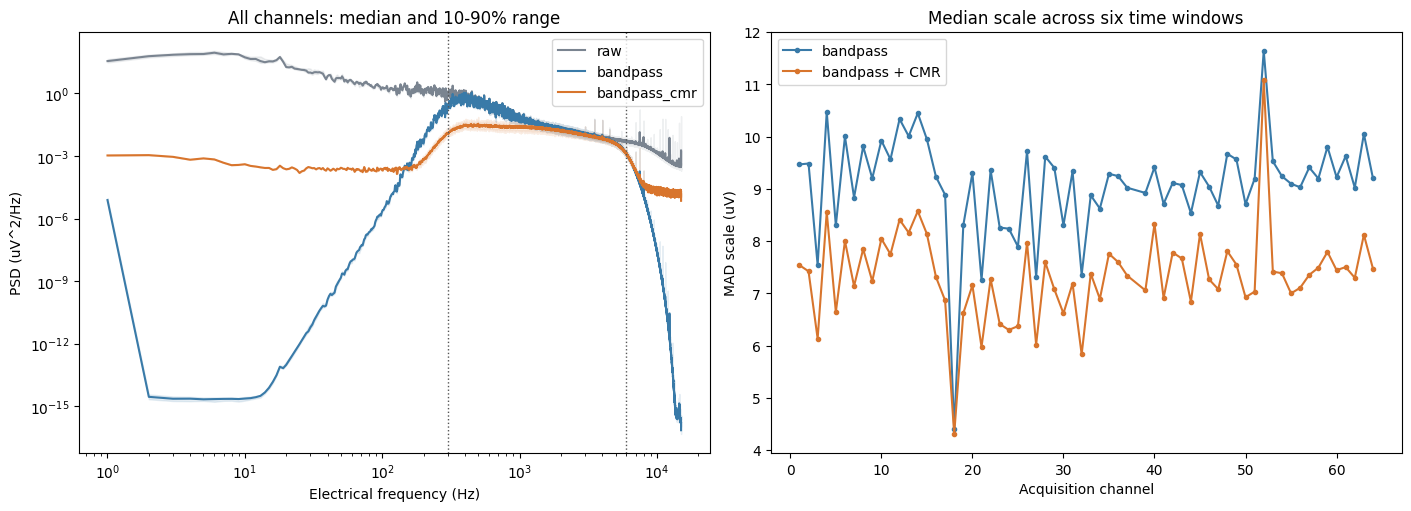

In [5]:
stage_names = ['raw', 'bandpass', 'bandpass_cmr']
spectra_sum = None
metric_rows = []

for window_index, start in enumerate(window_starts):
    raw_padded = read_voltage(start - padding_samples, start + window_samples + padding_samples)
    bp_padded, cmr_padded = preprocess(raw_padded)
    stages = np.stack([raw_padded[:, padding_samples:-padding_samples],
                       bp_padded[:, padding_samples:-padding_samples],
                       cmr_padded[:, padding_samples:-padding_samples]])
    for stage_index, stage_name in enumerate(stage_names):
        data = stages[stage_index]
        frequencies, psd = welch(data, fs=sample_rate, window='hann',
                                 nperseg=round(WELCH_SECONDS * sample_rate),
                                 noverlap=round(WELCH_SECONDS * sample_rate / 2),
                                 detrend='constant', scaling='density', axis=1)
        if spectra_sum is None:
            spectra_sum = np.zeros((len(stage_names), *psd.shape), dtype=np.float64)
        spectra_sum[stage_index] += psd
        centered = data - np.median(data, axis=1, keepdims=True)
        scales = np.median(np.abs(centered), axis=1) / 0.67448975
        powers = {}
        for name, low, high in [('below_300', 0, LOW_HZ), ('300_6000', LOW_HZ, HIGH_HZ), ('above_6000', HIGH_HZ, sample_rate / 2)]:
            mask = (frequencies >= low) & (frequencies <= high)
            powers[name] = trapezoid(psd[:, mask], frequencies[mask], axis=1)
        for row, channel in enumerate(active_channels):
            metric_rows.append({
                'window': window_index + 1, 'channel': int(channel), 'stage': stage_name,
                'mad_scale_uv': float(scales[row]),
                **{f'power_{name}_uv2': float(values[row]) for name, values in powers.items()},
            })

spectra = spectra_sum / N_WINDOWS
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(FILTER_RESULTS / 'preprocessing_metrics.csv', index=False)
np.savez_compressed(FILTER_RESULTS / 'spectra.npz',
                    frequency_hz=frequencies, channels=active_channels,
                    stages=np.array(stage_names), mean_psd_uv2_per_hz=spectra.astype(np.float32))

window_scales = metrics.pivot(index=['window', 'channel'], columns='stage', values='mad_scale_uv')
channel_scales = window_scales.groupby('channel').median()
final_scales = window_scales['bandpass_cmr'].unstack('channel')
scale_ratios = final_scales / final_scales.median(axis=0)
window_comparison = pd.DataFrame({
    'window': windows['window'], 'start_seconds': windows['start_seconds'],
    'min_ratio': scale_ratios.min(axis=1).to_numpy(),
    'median_ratio': scale_ratios.median(axis=1).to_numpy(),
    'max_ratio': scale_ratios.max(axis=1).to_numpy(),
})
window_comparison.to_csv(FILTER_RESULTS / 'window_scale_comparison.csv', index=False)
print('Range of channel median final MAD scales (uV):',
      round(channel_scales['bandpass_cmr'].min(), 3), 'to', round(channel_scales['bandpass_cmr'].max(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
colors = ['#7A8490', '#397AA8', '#D8752D']
for index, (stage, color) in enumerate(zip(stage_names, colors)):
    q10, middle, q90 = np.quantile(spectra[index], [0.1, 0.5, 0.9], axis=0)
    mask = frequencies > 0
    axes[0].loglog(frequencies[mask], middle[mask], color=color, label=stage)
    axes[0].fill_between(frequencies[mask], q10[mask], q90[mask], color=color, alpha=0.12)
axes[0].axvline(LOW_HZ, color='#555555', linestyle=':', linewidth=1)
axes[0].axvline(HIGH_HZ, color='#555555', linestyle=':', linewidth=1)
axes[0].set(xlabel='Electrical frequency (Hz)', ylabel='PSD (uV^2/Hz)', title='All channels: median and 10-90% range')
axes[0].legend()
axes[1].plot(channel_scales.index, channel_scales['bandpass'], 'o-', markersize=3, label='bandpass', color=colors[1])
axes[1].plot(channel_scales.index, channel_scales['bandpass_cmr'], 'o-', markersize=3, label='bandpass + CMR', color=colors[2])
axes[1].set(xlabel='Acquisition channel', ylabel='MAD scale (uV)', title='Median scale across six time windows')
axes[1].legend()
fig.savefig(FILTER_RESULTS / 'preprocessing_overview.png', dpi=170)
plt.show()

In [ ]:
from scipy.signal import find_peaks

THRESHOLD_MULTIPLIER = 4.5
MIN_PEAK_INTERVAL_MS = 1.0
min_peak_samples = round(MIN_PEAK_INTERVAL_MS * sample_rate / 1000)
CHUNK_SECONDS = 10
chunk_samples = round(CHUNK_SECONDS * sample_rate)
noise_scales = channel_scales.loc[active_channels, 'bandpass_cmr'].to_numpy()
if not np.all(np.isfinite(noise_scales) & (noise_scales > 0)):
    raise ValueError('Each retained channel needs a finite, positive noise scale.')

thresholds_uv = THRESHOLD_MULTIPLIER * noise_scales
event_batches = []

for start in range(0, valid_samples, chunk_samples):
    stop = min(start + chunk_samples, valid_samples)
    read_start = max(0, start - padding_samples)
    read_stop = min(valid_samples, stop + padding_samples)
    _, referenced = preprocess(read_voltage(read_start, read_stop))

    for channel, trace, threshold in zip(active_channels, referenced, thresholds_uv):
        for sign, polarity in ((1, 'positive'), (-1, 'negative')):
            peaks, _ = find_peaks(sign * trace, height=threshold, distance=min_peak_samples)
            samples = read_start + peaks
            keep = (samples >= start) & (samples < stop)
            if keep.any():
                event_batches.append(pd.DataFrame({
                    'sample_index': samples[keep],
                    'time_seconds': samples[keep] / sample_rate,
                    'channel': channel,
                    'amplitude_uv': trace[peaks[keep]],
                    'polarity': polarity,
                }))

columns = ['sample_index', 'time_seconds', 'channel', 'amplitude_uv', 'polarity']
events = pd.concat(event_batches, ignore_index=True) if event_batches else pd.DataFrame(columns=columns)
events = events.sort_values(['sample_index', 'channel'], ignore_index=True)
detection_dir = RESULTS_DIR / '03_peak_detection'
detection_dir.mkdir(exist_ok=True)
events.to_csv(detection_dir / 'candidate_peaks.csv', index=False)

In [ ]:
MERGE_DISTANCE = 30
MERGE_WINDOW_MS = 0.5
merge_window_samples = round(MERGE_WINDOW_MS * sample_rate / 1000)

peaks = pd.read_csv(RESULTS_DIR / '03_peak_detection' / 'candidate_peaks.csv')
peaks = peaks.sort_values(['sample_index', 'channel'], ignore_index=True)
samples = peaks['sample_index'].to_numpy()
amplitudes = peaks['amplitude_uv'].to_numpy()
contact_map = channels.set_index('channel')
coordinates = contact_map.loc[active_channels, ['map_x', 'map_y']].to_numpy()
contact_rows = pd.Index(active_channels).get_indexer(peaks['channel'])
if np.any(contact_rows < 0):
    raise ValueError('A candidate peak is on a channel outside the retained channel map.')

distances = np.linalg.norm(coordinates[:, None] - coordinates[None, :], axis=2)
neighbors = distances <= MERGE_DISTANCE
np.fill_diagonal(neighbors, False)
left_edges = np.searchsorted(samples, samples - merge_window_samples)
right_edges = np.searchsorted(samples, samples + merge_window_samples, side='right')

# Process the strongest remaining peak first. Every member must match that peak directly.
assigned = np.zeros(len(peaks), dtype=bool)
member_counts = np.zeros(len(peaks), dtype=int)
for peak in np.argsort(-np.abs(amplitudes), kind='stable'):
    if assigned[peak]:
        continue
    assigned[peak] = True
    left, right = left_edges[peak], right_edges[peak]
    eligible = ~assigned[left:right] & neighbors[contact_rows[peak], contact_rows[left:right]]
    assigned[left + np.flatnonzero(eligible)] = True
    member_counts[peak] = 1 + np.count_nonzero(eligible)

events = peaks.loc[member_counts > 0].copy()
events['peak_count'] = member_counts[member_counts > 0]
merge_dir = RESULTS_DIR / '04_event_merge'
merge_dir.mkdir(exist_ok=True)
events.to_csv(merge_dir / 'merged_events.csv', index=False)